# How OCR errors break clinical NER, and how to fix it: analysis

Scanned clinical documents reach an NER model only after OCR. This notebook measures what that costs a biomedical
tagger and compares three fixes, using the BC5CDR corpus (PubMed abstracts with every chemical and disease mention
annotated as a character span).

| Part | Question | Validation |
|---|---|---|
| Data | Does the corpus match its publication? | article and mention counts against Li et al. (2016); concept-level scorer against the corpus README |
| Scans | How bad are the five scan levels? | CER, WER and the fate of every gold mention |
| Tagger | Is the clean-text tagger a credible baseline? | PubMedBERT results published by Gu et al. (2021) on the same test set |
| Curve | How does entity F1 fall with CER? | bootstrap CIs over pages; slope with a bootstrap CI |
| Fixes | Do page clean-up, noise-augmented training and LLM correction help? | paired bootstrap over abstracts, Holm correction |

Every number below is read from the tables written by `scripts/run_pipeline.py`. Run settings:

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES, FIG = ROOT / 'reports' / 'results', ROOT / 'reports' / 'figures'
pd.set_option('display.precision', 4)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 180)
meta = json.loads((RES / 'run_metadata.json').read_text())
{k: meta[k] for k in ['settings', 'preprocessing_chosen', 'timings_s', 'pages_ocr_this_run', 'device']}

{'settings': {'test_docs': 60,
  'levels': [0, 1, 2, 3, 4],
  'channel_docs': 6,
  'pre_docs': 4,
  'pre_candidates': [['deskew'],
   ['deskew', 'nlmeans'],
   ['deskew', 'upscale', 'median', 'otsu']],
  'pre_levels': [4],
  'llm_docs': 8,
  'llm_levels': [3, 4],
  'llm_clean_docs': 4,
  'dev_docs': 150,
  'clean': {'model': 'microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract',
   'revision': 'd673b8835373c6fa116d6d8006b33d48734e305d',
   'epochs': 2,
   'lr': 5e-05,
   'batch': 16,
   'warmup': 0.1,
   'weight_decay': 0.01,
   'max_words': 80,
   'max_length': 256,
   'noise_prob': 0.0,
   'noise_cer': [0.005, 0.25],
   'subsample': 0},
  'noisy': {'model': 'microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract',
   'revision': 'd673b8835373c6fa116d6d8006b33d48734e305d',
   'epochs': 2,
   'lr': 5e-05,
   'batch': 16,
   'warmup': 0.1,
   'weight_decay': 0.01,
   'max_words': 80,
   'max_length': 256,
   'noise_prob': 0.5,
   'noise_cer': [0.005, 0.25],
   'subsample': 0},
  'n_boot'

## 1. Data and checks

The pinned archive matches every article and mention count of Table 1 in Li et al. (2016). The scorer is checked on
something independent: the archive ships the outputs of NCBI's tmChem and DNorm tools on the test set, with their
document-level concept scores in its README, and the scorer here reproduces them to two decimals. On clean text,
99.95% of test mentions start and end on word boundaries, so word-level tagging can match almost all of them exactly.

In [2]:
pd.read_csv(RES / 'data_crosscheck.csv')

,split,statistic,published,loaded,match
0,train,articles,500,500,True
1,train,Chemical mentions,5203,5203,True
2,train,Disease mentions,4182,4182,True
3,dev,articles,500,500,True
4,dev,Chemical mentions,5347,5347,True
5,dev,Disease mentions,4244,4244,True
6,test,articles,500,500,True
7,test,Chemical mentions,5385,5385,True
8,test,Disease mentions,4424,4424,True


In [3]:
pd.read_csv(RES / 'split_summary.csv')

,split,documents,words_mean,words_max,characters,chemical_mentions,disease_mentions,overlapping_mentions,non_ascii_characters,mentions_on_word_boundaries
0,train,500,186.048,535,652667,5203,4182,0,0,1.0000
1,dev,500,184.570,533,647019,5347,4244,0,0,0.9990
2,test,500,192.966,505,677248,5385,4424,0,0,0.9995


In [4]:
pd.read_csv(RES / 'scorer_check.csv')

,tool,type,concept_precision,concept_recall,concept_f1,readme_precision,readme_recall,readme_f1,match_to_2dp
0,tmChem,Chemical,0.9247,0.8989,0.9116,0.92,0.9,0.91,True
1,DNorm,Disease,0.8101,0.8023,0.8062,0.81,0.8,0.81,True


## 2. Synthetic scans

Each abstract is typeset at 300 dpi and degraded by a scanner model: skew, blur, down-sampling to 85-66 dpi, sensor
noise, speckle and JPEG compression. Level 0 is the clean 300 dpi page. The crops below show the same abstract at every
level, pixels 1:1.

In [5]:
pd.read_csv(RES / 'degradation_levels.csv')

,level,dpi,blur,noise,jpeg,skew,speckle
0,0,300,0.0,0.0,NaN,0.0,0.0000
1,1,85,1.6,16.0,50.0,0.8,0.0010
2,2,78,1.8,18.0,40.0,1.0,0.0020
3,3,72,2.0,20.0,35.0,1.2,0.0025
4,4,66,2.2,24.0,30.0,1.5,0.0030


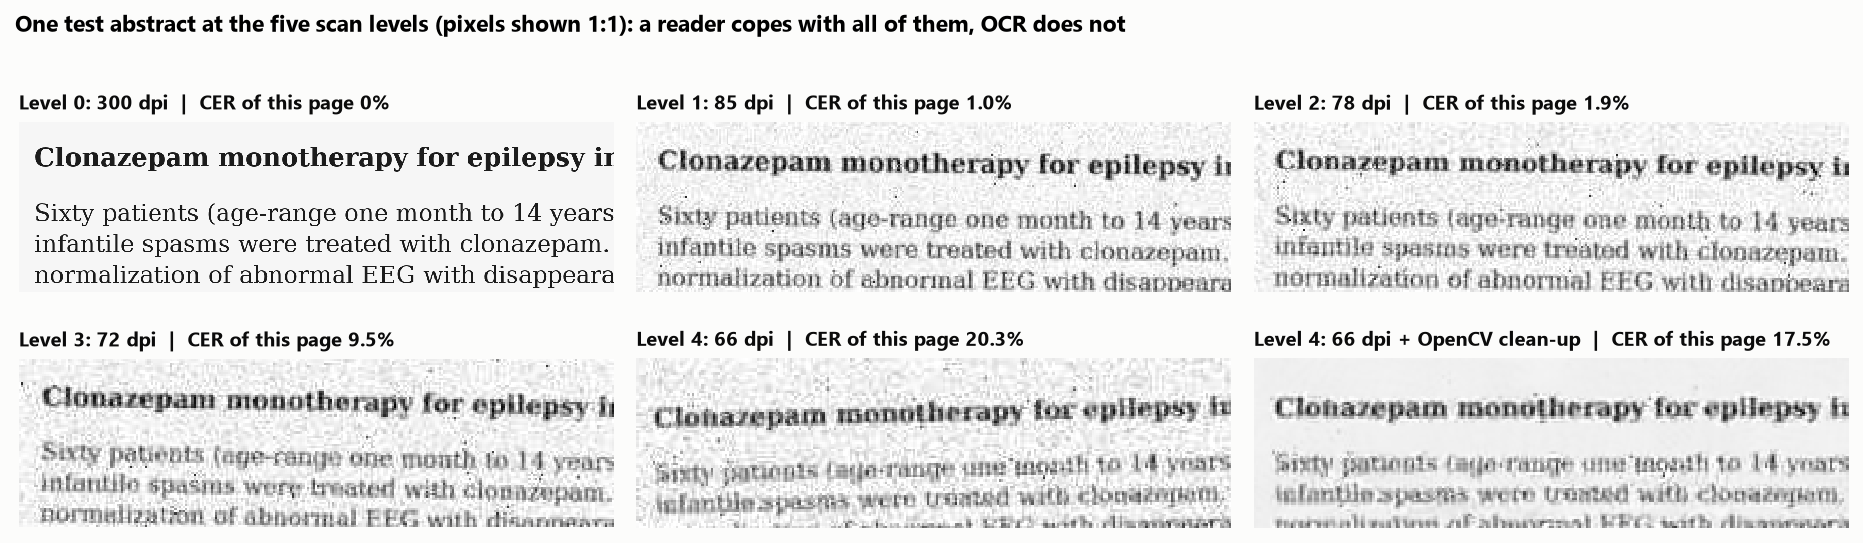

In [6]:
display(Image(FIG / '00_pages.png'))

## 3. Choosing the OpenCV clean-up on development pages

Three pipelines were OCR'd on four development abstracts at level 4. Deskew + non-local-means denoising has the lowest
CER and is applied to the test pages; Otsu binarisation after median filtering is worse than doing nothing, plausibly
because binarising a blurred 66 dpi page breaks thin strokes that the greyscale OCR model could still read.

In [7]:
pd.read_csv(RES / 'preprocessing_selection.csv')

,level,pipeline,cer,chosen
0,4,none,0.2066,False
1,4,deskew,0.1650,False
2,4,deskew+nlmeans,0.1486,True
3,4,deskew+upscale+median+otsu,0.2453,False


## 4. The OCR noise channel

Aligning the OCR output of six development abstracts (levels 1-4) with the clean text gives per-character deletion,
substitution and insertion rates. Lost spaces dominate, followed by lost full stops and hyphens and e/o, f/t, a/o
confusions. Sampling from the channel reproduces a target CER closely, and the span projection used for scoring
agrees with the generator's exact span tracking on 100%, 99.3% and 96.8% of mentions at 1%, 5% and 20% CER.

In [8]:
pd.read_csv(RES / 'noise_channel.csv').head(20)

,operation,reference,ocr,count,rate
0,delete,<space>,NaN,220,0.0425
1,substitute,e,o,87,0.0279
2,delete,.,NaN,66,0.1919
3,delete,i,NaN,53,0.0237
4,delete,-,NaN,35,0.1862
5,delete,n,NaN,35,0.0170
6,insert,NaN,i,35,0.0010
7,delete,l,NaN,33,0.0315
8,substitute,f,t,32,0.0544
9,substitute,a,o,32,0.0147


In [9]:
pd.read_csv(RES / 'channel_check.csv')

,target_cer,realized_cer,mentions,alignment_agrees,agreement
0,0.01,0.0102,751,751,1.0000
1,0.05,0.0474,751,746,0.9933
2,0.20,0.1887,751,727,0.9680


## 5. The two taggers

Both are PubMedBERT fine-tuned for 2 epochs on the 500 training abstracts with the same settings and number of steps;
the noise-augmented one sees a fresh noisy copy of half of the abstracts in every epoch. The epoch with the best F1 on
150 clean development abstracts is kept: epoch 2 for the clean-trained tagger, epoch 1 for the augmented one.

In [10]:
pd.read_csv(RES / 'models.csv')

,model,epochs_run,best_epoch,dev_f1,train_seconds,noise_prob,noise_cer_range
0,clean-trained,2,2,0.8840,38.5982,0.0,NaN
1,noise-augmented,2,1,0.8688,41.2138,0.5,0.005-0.25


In [11]:
pd.read_csv(RES / 'training_history.csv')

,epoch,train_loss,dev_f1,steps,seconds,model
0,1,0.1916,0.8655,121,16.9701,clean-trained
1,2,0.0420,0.8840,121,16.1549,clean-trained
2,1,0.2240,0.8688,118,19.2320,noise-augmented
3,2,0.0770,0.8654,119,19.4848,noise-augmented


## 6. Clean-text benchmark

On all 500 test abstracts the clean-trained tagger reaches 0.926 F1 on chemicals and 0.838 on diseases, 0.7 and 1.9
points below the PubMedBERT results of Gu et al. (2021), who trained one model per entity type with tuned
hyperparameters. It is well above the shipped tmChem and DNorm outputs and below the corpus' inter-annotator agreement.

In [12]:
pd.read_csv(RES / 'published_comparison.csv')

,system,type,precision,recall,f1,f1_low,f1_high,source
0,clean-trained PubMedBERT (this project),Chemical,0.9107,0.9415,0.9259,0.9138,0.9364,computed
1,clean-trained PubMedBERT (this project),Disease,0.8076,0.8698,0.8375,0.8196,0.8544,computed
2,clean-trained PubMedBERT (this project),both,0.8631,0.9092,0.8856,0.8756,0.8949,computed
3,noise-augmented PubMedBERT (this project),Chemical,0.9107,0.9339,0.9222,0.9087,0.9336,computed
4,noise-augmented PubMedBERT (this project),Disease,0.7709,0.8558,0.8111,0.7941,0.8268,computed
5,noise-augmented PubMedBERT (this project),both,0.8449,0.8987,0.8710,0.8602,0.8811,computed
6,tmChem output shipped with the corpus,Chemical,0.9634,0.8412,0.8982,NaN,NaN,computed from the archive
7,DNorm output shipped with the corpus,Disease,0.8141,0.7871,0.8004,NaN,NaN,computed from the archive
8,"PubMedBERT (uncased, abstracts), Gu et al. 2021",Chemical,NaN,NaN,0.9333,NaN,NaN,published (separate model per type)
9,"PubMedBERT (uncased, abstracts), Gu et al. 2021",Disease,NaN,NaN,0.8562,NaN,NaN,published (separate model per type)


## 7. Entity F1 by scan level

A clean scan costs nothing. From level 1 on the losses grow quickly: -1.7, -6.8, -17.2 and -43.8 points of exact F1 at
0.7%, 2.2%, 6.9% and 22% CER. WER runs 3-8 times above CER, because a single wrong character, a lost space or a lost
hyphen breaks a whole word, and disease names (often several words) lose more than chemical names.

In [13]:
s = pd.read_csv(RES / 'condition_summary.csv')
cols = ['model', 'condition', 'documents', 'cer', 'wer', 'mention_cer', 'intact_share', 'lost_share',
        'strict_precision', 'strict_recall', 'strict_f1', 'strict_f1_low', 'strict_f1_high',
        'strict_f1_chemical', 'strict_f1_disease', 'overlap_f1']
s[cols]

,model,condition,documents,cer,wer,mention_cer,intact_share,lost_share,strict_precision,strict_recall,strict_f1,strict_f1_low,strict_f1_high,strict_f1_chemical,strict_f1_disease,overlap_f1
0,clean-trained,clean text,60,0.0000,0.0000,0.0000,1.0000,0.0000,0.8928,0.9170,0.9047,0.8837,0.9235,0.9425,0.8580,0.9388
1,clean-trained,L0,60,0.0011,0.0049,0.0006,0.9925,0.0000,0.8928,0.9170,0.9047,0.8834,0.9237,0.9425,0.8580,0.9388
2,clean-trained,L1,60,0.0074,0.0583,0.0046,0.9543,0.0000,0.8785,0.8974,0.8879,0.8678,0.9078,0.9264,0.8404,0.9294
3,clean-trained,L2,60,0.0218,0.1553,0.0165,0.8321,0.0000,0.8396,0.8349,0.8372,0.8105,0.8649,0.8687,0.7979,0.9111
4,clean-trained,L3,60,0.0689,0.3376,0.0596,0.6035,0.0019,0.7666,0.7015,0.7326,0.7007,0.7638,0.7921,0.6555,0.8573
5,clean-trained,L4,60,0.2199,0.6913,0.2067,0.2425,0.0084,0.6274,0.3722,0.4672,0.4299,0.5035,0.5388,0.3580,0.6112
6,clean-trained,L4 + preprocessing,60,0.1557,0.6047,0.1573,0.2994,0.0000,0.6853,0.4813,0.5655,0.5277,0.6047,0.6433,0.4514,0.6981
7,clean-trained,L3 + LLM correction,8,0.0292,0.0648,0.0272,0.9076,0.0000,0.8154,0.8908,0.8514,0.7783,0.9084,0.9247,0.8077,0.9398
8,clean-trained,L4 + LLM correction,8,0.2435,0.4252,0.1740,0.6471,0.0168,0.6803,0.6975,0.6888,0.6027,0.7721,0.7640,0.6447,0.8299
9,clean-trained,L0 + LLM correction,4,0.0016,0.0064,0.0000,1.0000,0.0000,0.8413,0.9138,0.8760,0.7347,0.9722,1.0000,0.8193,0.9587


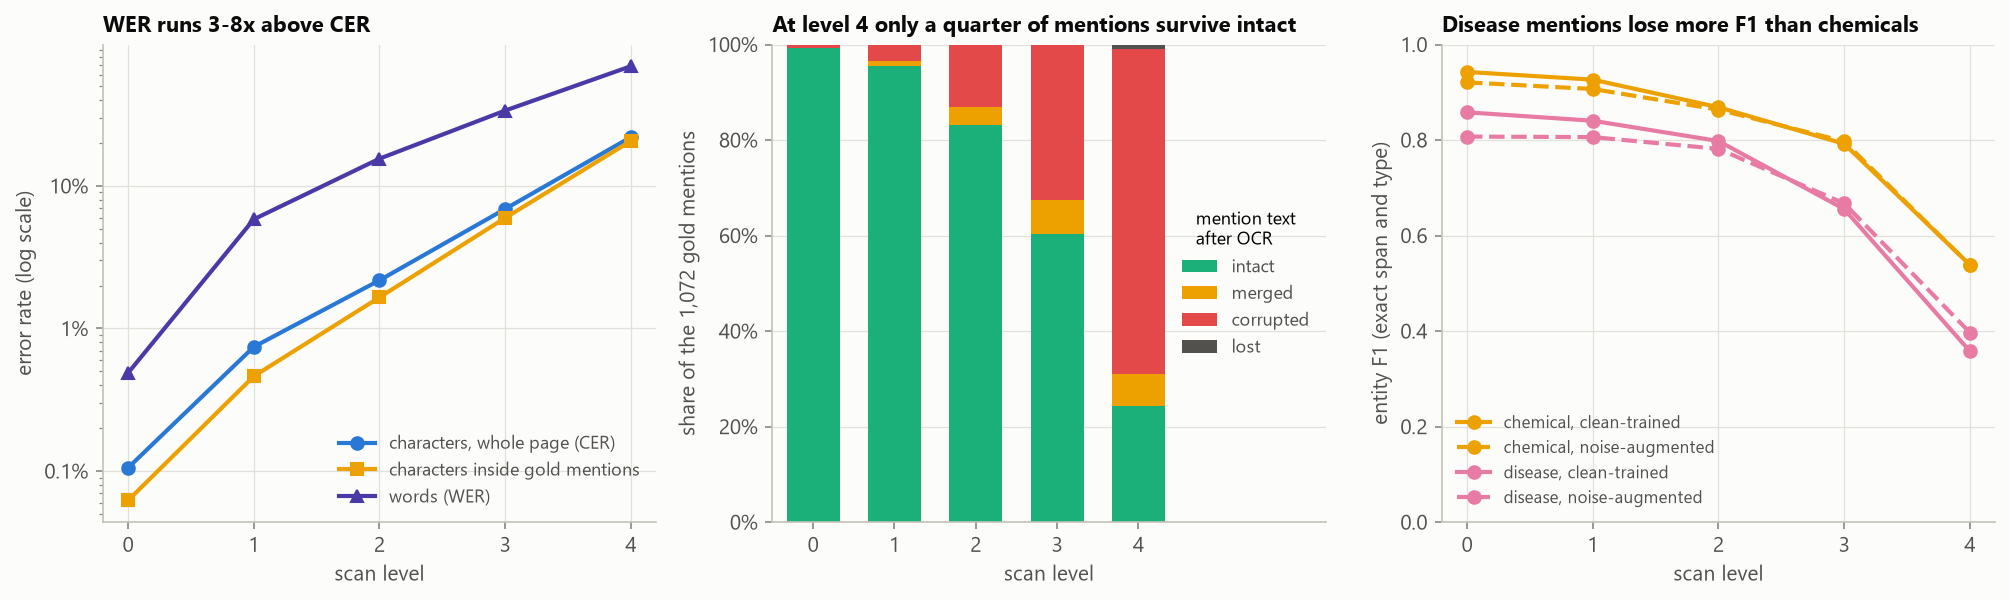

In [14]:
display(Image(FIG / '02_levels.png'))

## 8. F1 against CER

Binning the 300 raw-OCR pages by their own CER gives the curve in the hero figure. Up to 10% CER, each point of CER costs
about 2.4 points of exact-match F1 (slope -0.024, bootstrap CI -0.030 to -0.018). The noise-augmented tagger starts lower
and only catches up with the clean-trained tagger above about 5% CER.

In [15]:
b = pd.read_csv(RES / 'f1_vs_cer_bins.csv')
b[b.metric == 'strict_f1'].pivot_table(index=['cer_low', 'cer_high'], columns='model',
    values=['pages', 'cer', 'f1', 'f1_low', 'f1_high'], sort=False).round(4)

pages                           cer                            f1                        f1_low                       f1_high                
model            clean-trained noise-augmented clean-trained noise-augmented clean-trained noise-augmented clean-trained noise-augmented clean-trained noise-augmented
cer_low cer_high                                                                                                                                                      
0.0000  0.0025            53.0            53.0        0.0005          0.0005        0.9094          0.8766        0.8896          0.8475        0.9303          0.9035
0.0025  0.0100            58.0            58.0        0.0058          0.0058        0.8906          0.8643        0.8712          0.8397        0.9103          0.8875
0.0100  0.0250            58.0            58.0        0.0176          0.0176        0.8512          0.8272        0.8292          0.7989        0.8727          0.8539
0.0250  0.0500            20.0            20.0        0.0361          0.0361        0.7977          0.7914        0.7296          0.7322        0.8572          0.8497
0.0500  0.1000            46.0            46.0        0.0676          0.0676        0.7323          0.7422        0.6962          0.7086        0.7698          0.7784
0.1000  0.2000            33.0            33.0        0.1760          0.1760        0.5611          0.5753        0.5094          0.5287        0.6119          0.6262
0.2000  1.0000            32.0            32.0        0.2469          0.2469        0.4150          0.4253        0.3738          0.3856        0.4546          0.4662

In [16]:
pd.read_csv(RES / 'f1_cer_slope.csv')

,model,pages,cer_max,f1_per_cer_point,ci_low,ci_high
0,clean-trained,235,0.1,-0.0242,-0.0304,-0.0184
1,noise-augmented,235,0.1,-0.0185,-0.0254,-0.0125


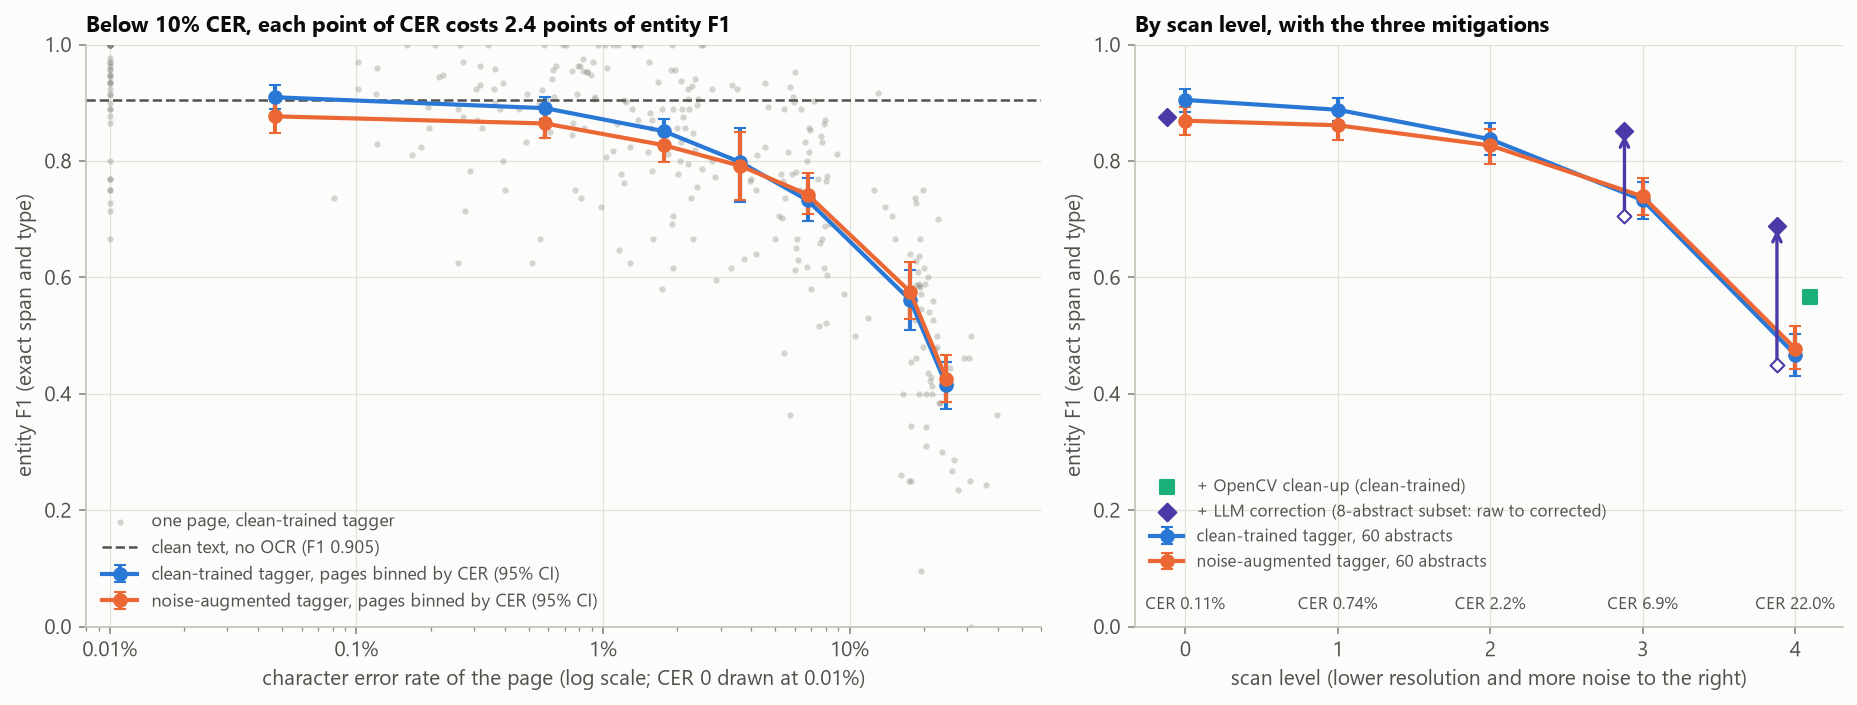

In [17]:
display(Image(FIG / '01_f1_vs_cer.png'))

## 9. Why F1 falls: the fate of each mention

Mentions whose characters come through intact (and stay separate words) are found almost as often as on clean text,
so damage to the surrounding context is a small effect. Corrupted mentions are found far less often, and mentions glued
to a neighbouring word can never be matched exactly by a word-level tagger. The noise-augmented tagger finds more
corrupted and glued mentions approximately, which is why its overlap F1 improves at levels 3-4 while its exact F1 does
not.

In [18]:
m = pd.read_csv(RES / 'mention_status.csv')
m[m.type == 'all'].pivot_table(index=['condition', 'status'], columns='model',
    values=['mentions', 'found_strict', 'found_overlap'], sort=False).round(3)

mentions                  found_strict                 found_overlap                
model                         clean-trained noise-augmented clean-trained noise-augmented clean-trained noise-augmented
condition           status                                                                                             
L0                  corrupted           7.0             7.0         0.857           0.857         0.857           0.857
                    intact           1064.0          1064.0         0.918           0.883         0.954           0.935
                    merged              1.0             1.0         0.000           0.000         1.000           1.000
L0 + LLM correction intact             58.0            58.0         0.914           0.914         1.000           0.983
L1                  corrupted          36.0            36.0         0.722           0.833         0.806           0.917
                    intact           1023.0          1023.0         0.915           0.887         0.953           0.943
                    merged             13.0            13.0         0.000           0.000         0.385           0.462
L2                  corrupted         140.0           140.0         0.571           0.643         0.793           0.850
                    intact            892.0           892.0         0.914           0.901         0.950           0.944
                    merged             40.0            40.0         0.000           0.000         0.450           0.725
L3                  corrupted         348.0           348.0         0.506           0.629         0.713           0.839
                    intact            647.0           647.0         0.890           0.879         0.927           0.927
                    merged             75.0            75.0         0.000           0.000         0.467           0.627
                    lost                2.0             2.0         0.000           0.000         0.000           0.000
L3 + LLM correction corrupted          11.0            11.0         0.455           0.636         0.909           0.909
                    intact            108.0           108.0         0.935           0.926         1.000           1.000
L4                  corrupted         730.0           730.0         0.262           0.404         0.395           0.667
                    intact            260.0           260.0         0.800           0.850         0.831           0.896
                    merged             73.0            73.0         0.000           0.000         0.329           0.521
                    lost                9.0             9.0         0.000           0.000         0.000           0.000
L4 + LLM correction corrupted          40.0            40.0         0.250           0.325         0.575           0.575
                    intact             77.0            77.0         0.948           0.909         1.000           1.000
                    lost                2.0             2.0         0.000           0.000         0.000           0.000
L4 + preprocessing  corrupted         677.0           677.0         0.365           0.523         0.505           0.727
                    intact            321.0           321.0         0.838           0.822         0.854           0.882
                    merged             74.0            74.0         0.000           0.000         0.365           0.662
clean text          intact           1072.0          1072.0         0.917           0.882         0.954           0.936

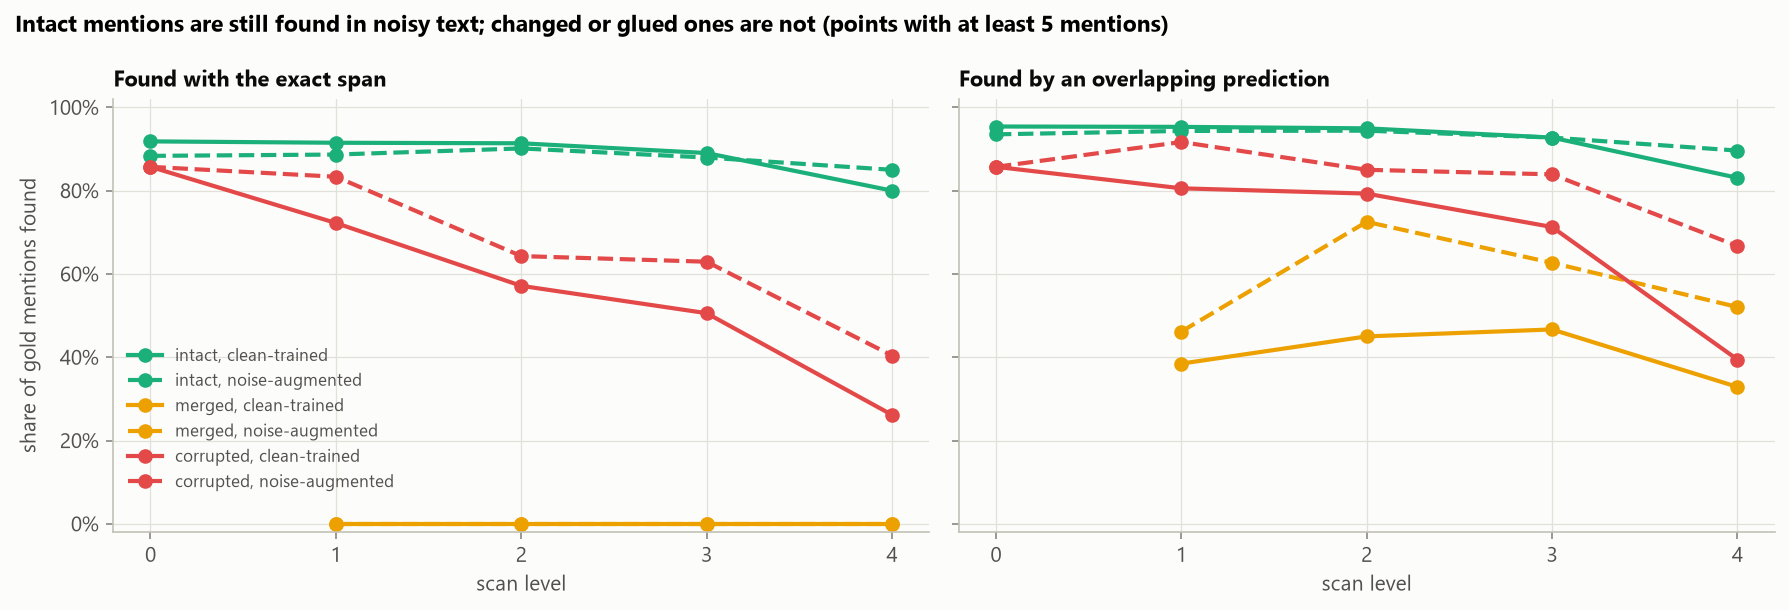

In [19]:
display(Image(FIG / '04_mention_fate.png'))

## 10. The three fixes, paired on the same pages

Holm correction is applied within each metric over 20 comparisons. Page clean-up adds about 10 points of exact F1 at
level 4 for either tagger. Noise-augmented training costs 3.6 points on clean text and gains nothing on exact matches,
but adds 7.5 points of overlap F1 at level 4. LLM correction gives the largest gains on its small subset.

In [20]:
sig = pd.read_csv(RES / 'significance.csv')
sig[sig.metric == 'strict_f1'][['family', 'model_a', 'condition_a', 'model_b', 'condition_b', 'documents',
    'f1_a', 'f1_b', 'diff', 'ci_low', 'ci_high', 'p', 'p_holm']].round(4)

,family,model_a,condition_a,model_b,condition_b,documents,f1_a,f1_b,diff,ci_low,ci_high,p,p_holm
0,OCR vs clean text,clean-trained,L0,clean-trained,clean text,60,0.9047,0.9047,0.0000,-0.0027,0.0027,1.0000,1.0000
2,OCR vs clean text,clean-trained,L1,clean-trained,clean text,60,0.8879,0.9047,-0.0169,-0.0259,-0.0068,0.0007,0.0056
4,OCR vs clean text,clean-trained,L2,clean-trained,clean text,60,0.8372,0.9047,-0.0675,-0.0833,-0.0529,0.0000,0.0000
6,OCR vs clean text,clean-trained,L3,clean-trained,clean text,60,0.7326,0.9047,-0.1722,-0.1990,-0.1453,0.0000,0.0000
8,OCR vs clean text,clean-trained,L4,clean-trained,clean text,60,0.4672,0.9047,-0.4375,-0.4780,-0.3984,0.0000,0.0000
10,noise-augmented vs clean-trained,noise-augmented,clean text,clean-trained,clean text,60,0.8691,0.9047,-0.0357,-0.0541,-0.0194,0.0000,0.0005
12,noise-augmented vs clean-trained,noise-augmented,L0,clean-trained,L0,60,0.8691,0.9047,-0.0357,-0.0541,-0.0194,0.0000,0.0005
14,noise-augmented vs clean-trained,noise-augmented,L1,clean-trained,L1,60,0.8612,0.8879,-0.0267,-0.0465,-0.0102,0.0032,0.0227
16,noise-augmented vs clean-trained,noise-augmented,L2,clean-trained,L2,60,0.8266,0.8372,-0.0106,-0.0282,0.0078,0.2655,1.0000
18,noise-augmented vs clean-trained,noise-augmented,L3,clean-trained,L3,60,0.7389,0.7326,0.0063,-0.0130,0.0277,0.5437,1.0000


In [21]:
sig[sig.metric == 'overlap_f1'][['family', 'model_a', 'condition_a', 'condition_b', 'diff', 'ci_low', 'ci_high', 'p']].round(4)

,family,model_a,condition_a,condition_b,diff,ci_low,ci_high,p
1,OCR vs clean text,clean-trained,L0,clean text,0.0000,0.0000,0.0000,1.0000
3,OCR vs clean text,clean-trained,L1,clean text,-0.0094,-0.0171,-0.0024,0.0114
5,OCR vs clean text,clean-trained,L2,clean text,-0.0277,-0.0404,-0.0161,0.0000
7,OCR vs clean text,clean-trained,L3,clean text,-0.0815,-0.0999,-0.0641,0.0000
9,OCR vs clean text,clean-trained,L4,clean text,-0.3276,-0.3692,-0.2899,0.0000
11,noise-augmented vs clean-trained,noise-augmented,clean text,clean text,-0.0201,-0.0303,-0.0097,0.0002
13,noise-augmented vs clean-trained,noise-augmented,L0,L0,-0.0201,-0.0303,-0.0097,0.0002
15,noise-augmented vs clean-trained,noise-augmented,L1,L1,-0.0084,-0.0191,0.0014,0.0938
17,noise-augmented vs clean-trained,noise-augmented,L2,L2,0.0015,-0.0076,0.0104,0.7454
19,noise-augmented vs clean-trained,noise-augmented,L3,L3,0.0185,0.0074,0.0297,0.0023


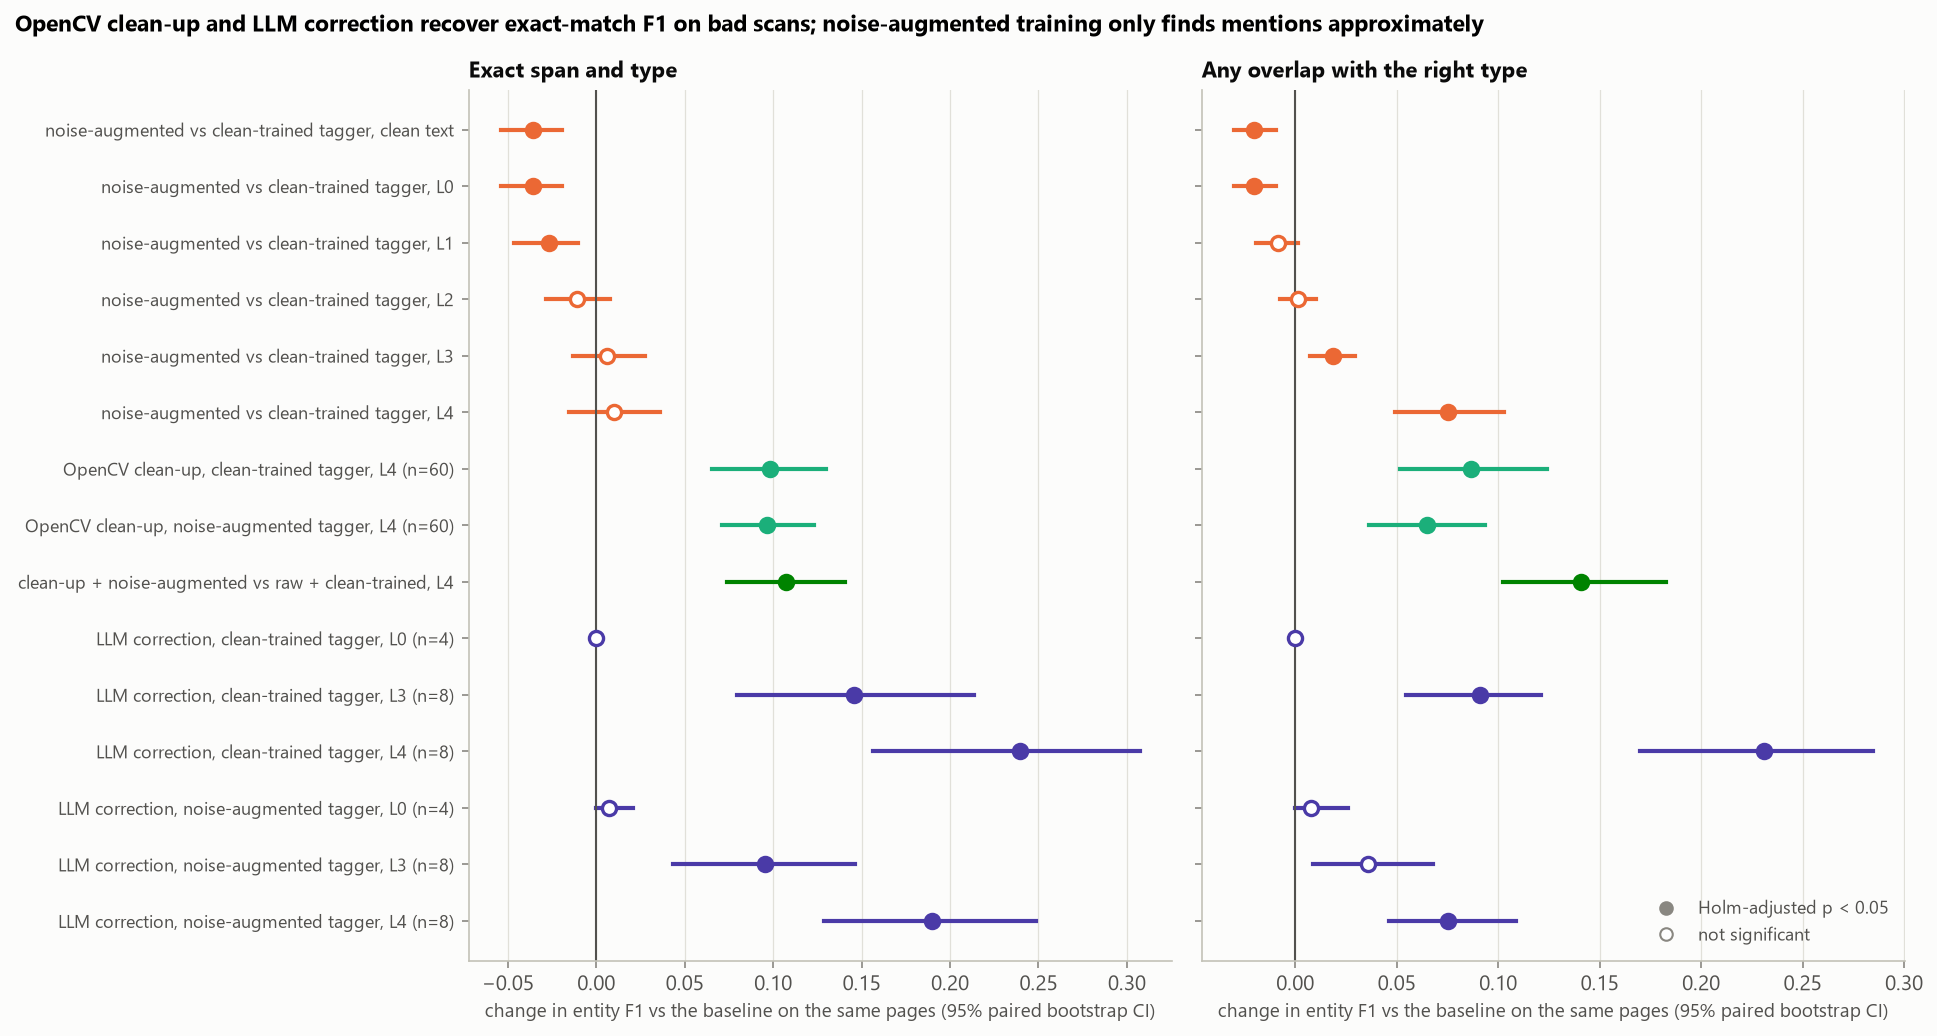

In [22]:
display(Image(FIG / '03_mitigations.png'))

## 11. LLM post-correction in detail

On 8 abstracts per level, qwen3:4b halves the CER at level 3 and cuts WER by four fifths. At level 4 it does not lower
CER on average (it rewrites or drops passages it cannot read), yet WER falls from 70% to 43% and the share of intact
mentions triples, which lifts exact F1 by 24 points. On four near-clean abstracts it changed a handful of characters
and no mention. No abstract lost F1, but 20 abstracts cannot rule out occasional harmful rewrites.

In [23]:
llm = pd.read_csv(RES / 'llm_correction.csv')
llm.groupby('level')[['cer_before', 'cer_after', 'f1_before_clean-trained', 'f1_after_clean-trained',
    'f1_before_noise-augmented', 'f1_after_noise-augmented', 'model_seconds']].mean().round(4)

,cer_before,cer_after,f1_before_clean-trained,f1_after_clean-trained,f1_before_noise-augmented,f1_after_noise-augmented,model_seconds
level,,,,,,,
0,0.0000,0.0015,0.8562,0.8562,0.8447,0.8514,4.2967
3,0.0661,0.0356,0.7101,0.8370,0.7447,0.8292,6.0827
4,0.2165,0.2322,0.4653,0.6947,0.5042,0.6751,5.1386


In [24]:
llm.assign(better=llm.cer_after < llm.cer_before, worse=llm.cer_after > llm.cer_before).groupby('level')[['better', 'worse']].sum()

,better,worse
level,,
0,0,3
3,7,1
4,3,4


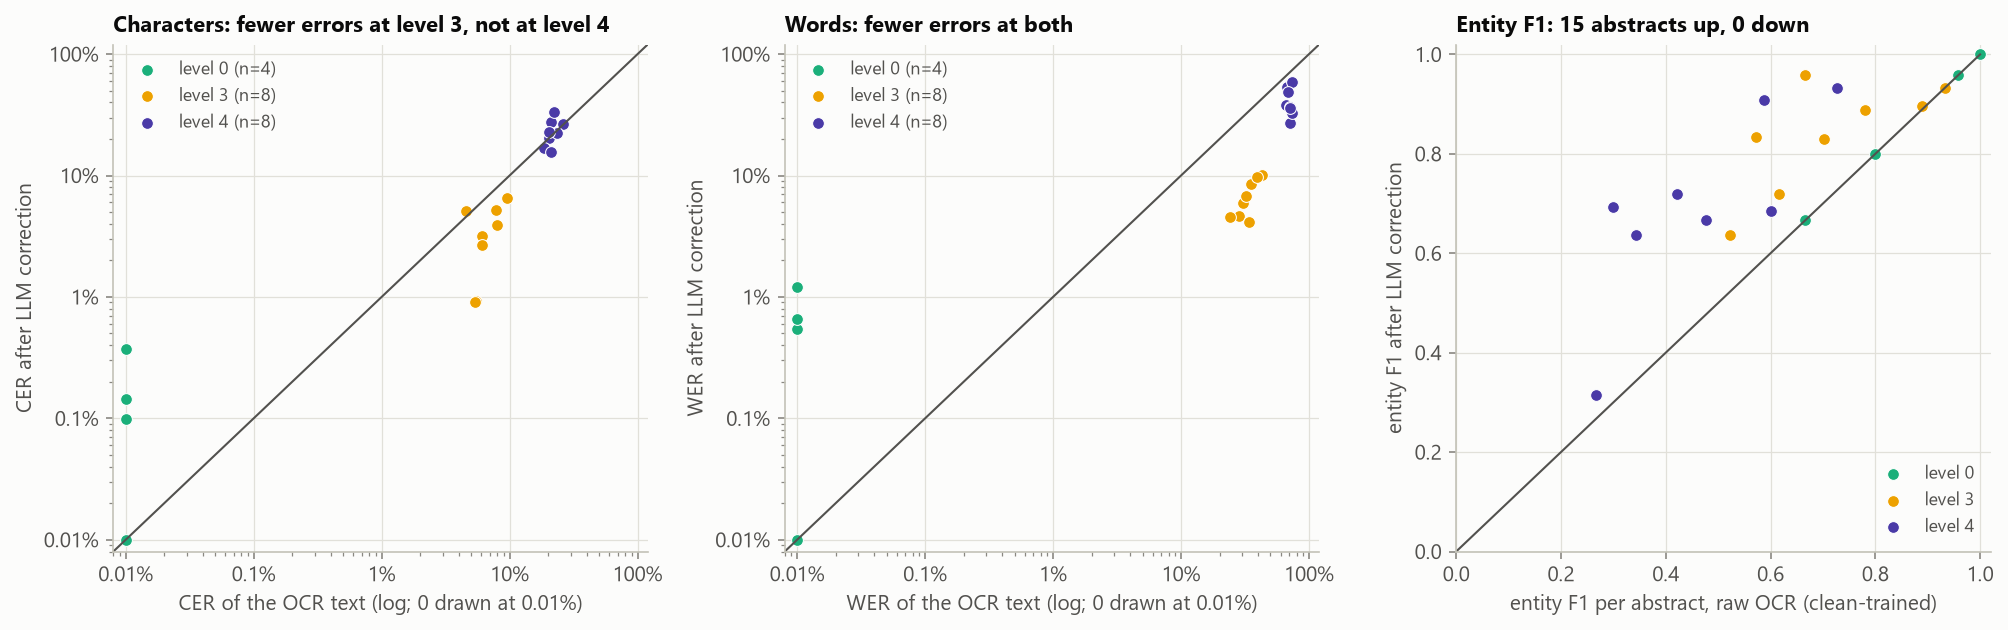

In [25]:
display(Image(FIG / '05_llm_correction.png'))

## 12. One abstract through the pipeline

The start of one test abstract as clean text, as OCR output at level 2 and level 4, after page clean-up and after LLM
correction.

In [26]:
ex = pd.read_csv(RES / 'examples.csv')
for r in ex[ex.model == 'clean-trained'].itertuples():
    print(f'--- {r.condition} (CER {r.cer:.2%})')
    print(r.text[:400])

--- clean text (CER 0.00%)
Clonazepam monotherapy for epilepsy in childhood. Sixty patients (age-range one month to 14 years) with other types of epilepsy than infantile spasms were treated with clonazepam. Disappearance of seizures and normalization of abnormal EEG with disappearance of seizures were recognized in 77% and 50%, respectively. Seizures disappeared in 71% of the patients with generalized seizures and 89% of pa
--- L2 (CER 1.90%)
Clonazepam monotherapy for epilepsy in childhood. Sixty patients (ageirange one month to 14 years) with other types of epilepsy than infantile spasmas were treated with conazepam. Disappearance of seizures and normalization of abnormal EEG withr disappearance of seizures were recognized in 77% and 50%, respectively, Seizures disappeared in 71% of the patients with generalized seizures and 89% of p
--- L4 (CER 20.30%)
Clonazepam monotherapy forepilepsy in childhood. Sixty patients fage-range ueinontti to 14 ynarsi withy other lypos of epitepny shan

## Takeaways

- Report entity-level F1 next to CER: a page with 2% CER already costs about 7 points of exact-match F1, and the tagger
  mostly misses damaged mentions rather than inventing new ones.
- Clean the page before OCR (deskew and denoise; do not binarise for a neural OCR model): about +10 points at the worst
  level for no model change.
- LLM post-correction recovers the most, especially at heavy noise, but costs about 5 s of GPU time per abstract and
  can rewrite text; it should be validated on a larger set before use, with a check for invented drug names.
- Training on synthetic character noise did not improve exact matches here and cost accuracy on clean text; it is worth
  it only where approximate detection is enough.
- Limitations: synthetic scans with one font and one OCR engine, 60 scanned abstracts (8 for the LLM), PubMed
  abstracts rather than clinical notes, and one configuration of noise augmentation.